# 🚕 NYC Yellow Taxi 2023 – Exploratory Data Analysis

**Author:** Paras Tomar · MIS Executive | Data Analyst

### Business problem
A new taxi operator in New York City wants to use 2023 trip data to decide **where and when to place cabs**, **how to price trips**, and **what affects customer tipping**.

### What this notebook covers
1. Data preparation – loading a 5% sample of all 2023 Yellow Taxi trips
2. Data cleaning – column fixes, missing values, outliers
3. Exploratory analysis – demand over time, revenue, pricing, zones, tips
4. Conclusions and recommendations

## Data Understanding
The yellow taxi trip records contain pickup and drop-off date/time, pickup and drop-off zones, trip distance, itemised fares, rate type, payment type and driver-reported passenger count.

- **Source:** [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) – one Parquet file per month.
- **Used here:** a 5% random sample of all 12 months of 2023, saved as a single Parquet file.

###  Data Description
You can find the data description here: [Data Dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

`PULocationID` and `DOLocationID` are zone numbers (1–263). They are joined with the TLC zone lookup table further below so charts can show zone names instead of only numbers.

---
## 1. Data Preparation

In [ ]:
# Libraries
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max.columns", None)

# Paths – put the sample Parquet file inside a `data/` folder next to this notebook
DATA_PATH = "data/NYC_Taxi_Sample_5pct.parquet"
SAMPLE_FRACTION = 0.05          # the sample is 5% of all 2023 trips
os.makedirs("images", exist_ok=True)

### 1.1 Load the dataset

In [ ]:
PD = pd.read_parquet(DATA_PATH)
PD.sample(5)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,Airport_fee
834158,2,2023-06-02 12:52:40,2023-06-02 13:08:30,2.0,1.89,1.0,N,68,230,1,14.9,0.0,0.5,2.00,0.0,1.0,20.90,2.5,NaN,0.00
406847,1,2023-11-19 16:56:43,2023-11-19 17:06:35,1.0,1.50,1.0,N,234,211,1,10.7,2.5,0.5,2.00,0.0,1.0,16.70,2.5,NaN,0.00
358829,2,2023-11-19 00:34:12,2023-11-19 01:25:30,1.0,8.47,1.0,N,231,74,1,50.6,1.0,0.5,13.90,0.0,1.0,69.50,2.5,NaN,0.00
1196941,2,2023-02-28 23:25:56,2023-02-28 23:46:26,1.0,5.79,1.0,N,138,192,1,26.8,6.0,0.5,2.00,0.0,1.0,37.55,0.0,NaN,1.25
1365540,2,2023-04-21 23:13:21,2023-04-21 23:34:07,1.0,3.23,1.0,N,100,263,1,20.5,1.0,0.5,3.82,0.0,1.0,29.32,2.5,NaN,0.00


In [ ]:
PD.shape

(1896427, 20)

### 1.2 Taxi zone names
The TLC publishes a small lookup table that maps each zone ID to its borough and zone name. If the download fails (no internet), the analysis still runs and shows zone IDs.

In [ ]:
ZONE_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
try:
    zones = pd.read_csv(ZONE_URL)
    zone_names = zones.set_index("LocationID")["Zone"].to_dict()
    print(f"Loaded {len(zone_names)} zone names")
except Exception as e:
    zone_names = {}
    print("Zone lookup not available, using zone IDs only:", e)


def zone_label(zone_id):
    """Return 'Zone name (ID)' if the name is known, otherwise the ID."""
    name = zone_names.get(int(zone_id))
    return f"{name} ({int(zone_id)})" if name else str(int(zone_id))

---
## 2. Data Cleaning
First, a basic look at data types, missing values and summary statistics.

In [ ]:
PD.isnull().sum()

VendorID                       0
tpep_pickup_datetime           0
tpep_dropoff_datetime          0
passenger_count            64924
trip_distance                  0
RatecodeID                 64924
store_and_fwd_flag         64924
PULocationID                   0
DOLocationID                   0
payment_type                   0
fare_amount                    0
extra                          0
mta_tax                        0
tip_amount                     0
tolls_amount                   0
improvement_surcharge          0
total_amount                   0
congestion_surcharge       64924
airport_fee              1747907
Airport_fee               213444
dtype: int64

In [ ]:
PD.dtypes

VendorID                          int64
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag                  str
PULocationID                      int64
DOLocationID                      int64
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
airport_fee                     float64
Airport_fee                     float64
dtype: object

In [ ]:
PD.info()

<class 'pandas.DataFrame'>
RangeIndex: 1896427 entries, 0 to 1896426
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee            float64   

In [ ]:
PD.describe().T

,count,mean,min,25%,50%,75%,max,std
VendorID,1896427.0,1.736307,1.0,1.0,2.0,2.0,6.0,0.446046
tpep_pickup_datetime,1896427,2023-07-02 20:03:31.073996,2001-01-01 00:06:49,2023-04-02 16:24:36,2023-06-27 15:13:55,2023-10-06 19:56:07,2023-12-31 23:58:14,NaN
tpep_dropoff_datetime,1896427,2023-07-02 20:21:03.739193,2001-01-01 15:42:11,2023-04-02 16:46:50,2023-06-27 15:32:30,2023-10-06 20:14:15.500000,2024-01-01 23:02:22,NaN
passenger_count,1831503.0,1.369667,0.0,1.0,1.0,1.0,9.0,0.893926
trip_distance,1896427.0,4.163961,0.0,1.05,1.79,3.4,186514.09,253.789372
RatecodeID,1831503.0,1.650204,1.0,1.0,1.0,1.0,99.0,7.486294
PULocationID,1896427.0,165.219977,1.0,132.0,162.0,234.0,265.0,64.002095
DOLocationID,1896427.0,163.994606,1.0,113.0,162.0,234.0,265.0,69.891818
payment_type,1896427.0,1.163072,0.0,1.0,1.0,1.0,4.0,0.507818
fare_amount,1896427.0,19.897127,0.0,9.3,13.5,22.29,2194.7,18.501055


### 2.1 Fixing columns
**Drop unneeded columns.** `store_and_fwd_flag` is not used in this analysis.

In [ ]:
# Fix the index and drop any columns that are not needed

PD.drop(columns=['Unnamed: 0', 'store_and_fwd_flag'], errors='ignore', inplace=True)

**Merge the two airport fee columns.** The raw files use both `Airport_fee` and `airport_fee` (a naming change between months), so they are combined into one column.

In [ ]:
# Combine the two airport fee columns

PD['airport_fee'] = PD['Airport_fee'].fillna(PD['airport_fee'])
PD.drop(columns=['Airport_fee'], inplace=True, errors='ignore')

In [ ]:
PD.head(5)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,1,2023-01-05 07:50:08,2023-01-05 08:02:04,2.0,1.90,1.0,239,236,1,13.5,2.5,0.5,2.50,0.0,1.0,20.00,2.5,0.0
1,2,2023-01-17 07:47:24,2023-01-17 08:00:50,5.0,1.86,1.0,239,162,1,14.2,0.0,0.5,3.64,0.0,1.0,21.84,2.5,0.0
2,2,2023-01-25 21:57:59,2023-01-25 22:00:33,1.0,0.50,1.0,162,170,1,5.1,1.0,0.5,2.02,0.0,1.0,12.12,2.5,0.0
3,2,2023-01-09 19:36:54,2023-01-09 19:52:01,2.0,2.56,1.0,162,262,1,17.0,2.5,0.5,4.70,0.0,1.0,28.20,2.5,0.0
4,1,2023-01-11 22:19:13,2023-01-11 22:32:37,1.0,2.80,1.0,164,231,1,14.9,3.5,0.5,3.98,0.0,1.0,23.88,2.5,0.0


**Check monetary columns for negative values.** Negative amounts usually mean refunds or data-entry errors.

In [ ]:
money_cols = ["fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount",
              "improvement_surcharge", "total_amount", "congestion_surcharge", "airport_fee"]
negatives = (PD[money_cols] < 0).sum()
print(negatives)

# Clip any negatives to 0 so they cannot distort revenue totals
PD[money_cols] = PD[money_cols].clip(lower=0)

No negative fares were found in this sample, so the clip step does not change any rows here. It is kept so the notebook also works on other samples.

### 2.2 Handling missing values
Proportion of missing values in each column:

In [ ]:
# Find the proportion of missing values in each column
PD.isnull().mean()

VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          0.034235
trip_distance            0.000000
RatecodeID               0.034235
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
fare_amount              0.000000
extra                    0.000000
mta_tax                  0.000000
tip_amount               0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     0.034235
airport_fee              0.034235
dtype: float64

`passenger_count`, `RatecodeID`, `congestion_surcharge` and `airport_fee` are each missing in the same **3.4%** of rows – these are trips where the vendor did not send those fields.

- `passenger_count` → filled with the median (1 passenger)
- `RatecodeID`, `congestion_surcharge`, `airport_fee` → filled with 0 (unknown / not charged)

In [ ]:
PD["passenger_count"] = PD["passenger_count"].fillna(PD["passenger_count"].median())
PD["RatecodeID"] = PD["RatecodeID"].fillna(0)
PD["congestion_surcharge"] = PD["congestion_surcharge"].fillna(0)
PD.fillna(0, inplace=True)

PD.isnull().sum().sum()   # should be 0

In [ ]:
# Trips with 0 passengers (driver did not enter a count)
zero_pax = (PD["passenger_count"] == 0).sum()
print(f"Trips with passenger_count = 0: {zero_pax:,} ({zero_pax / len(PD):.2%})")

Zero-passenger trips are kept for demand and revenue analysis (the trip still happened), but are excluded from any *per-passenger* calculation.

### 2.3 Handling outliers

In [ ]:
PD.describe().T

Trips with more than 6 passengers are very rare and are removed.

In [ ]:
PD = PD[PD["passenger_count"] <= 6]
PD.shape

In [ ]:
# Trip duration in minutes (needed to spot impossible trips)
PD["trip_duration"] = (PD["tpep_dropoff_datetime"] - PD["tpep_pickup_datetime"]).dt.total_seconds() / 60

outlier_rules = {
    "distance ~0 but fare > $300":   (PD["trip_distance"] < 0.1) & (PD["fare_amount"] > 300),
    "distance > 250 miles":          PD["trip_distance"] > 250,
    "duration <= 0 minutes":         PD["trip_duration"] <= 0,
    "duration > 24 hours":           PD["trip_duration"] > 24 * 60,
    "fare > $1,000":                 PD["fare_amount"] > 1000,
}
for rule, mask in outlier_rules.items():
    print(f"{rule:<32} {mask.sum():>8,}")

bad_rows = np.logical_or.reduce(list(outlier_rules.values()))
print(f"\nRemoving {bad_rows.sum():,} rows ({bad_rows.mean():.3%} of data)")
PD = PD[~bad_rows].copy()
PD.shape

These rows are recording errors (a trip cannot end before it starts or cover 250+ miles inside NYC), so they are dropped. They are a tiny share of the data.

---
## 3. Exploratory Data Analysis
### 3.1 General EDA: patterns and trends

**Variable types**

| Type | Columns |
|---|---|
| Categorical | `VendorID`, `RatecodeID`, `PULocationID`, `DOLocationID`, `payment_type`, `pickup_hour`, day of week, month |
| Numerical | `passenger_count`, `trip_distance`, `trip_duration`, `fare_amount`, `extra`, `mta_tax`, `tip_amount`, `tolls_amount`, `improvement_surcharge`, `total_amount`, `congestion_surcharge`, `airport_fee` |
| Date/time | `tpep_pickup_datetime`, `tpep_dropoff_datetime` |

`passenger_count` is a count, but it has only 0–6 values, so it is also used as a category in some charts.

#### Temporal analysis
Pickups by hour of day:

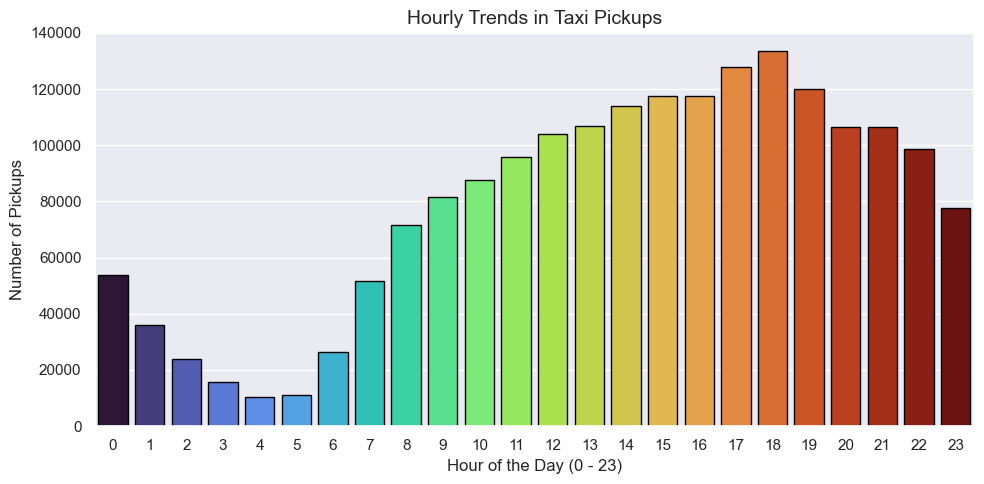

In [ ]:
# Find and show the hourly trends in taxi pickups

Hourly_trends=PD['tpep_pickup_datetime'].dt.hour.value_counts().sort_index().reset_index()
Hourly_trends.columns=["Hour","Count"]
plt.figure(figsize=(10, 5))
sns.barplot(data=Hourly_trends, x='Hour',  y='Count',  hue='Hour',palette='turbo',legend=False, edgecolor='black')    
plt.title("Hourly Trends in Taxi Pickups", fontsize=14)
plt.xlabel("Hour of the Day (0 - 23)", fontsize=12)
plt.ylabel("Number of Pickups", fontsize=12)
plt.tight_layout()
plt.savefig("images/hourly_trends_in_taxi.png", dpi=300, bbox_inches="tight") 
plt.show()   
   

Pickups by day of week:

In [ ]:
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_trends = (PD["tpep_pickup_datetime"].dt.day_name()
                .value_counts().reindex(days_order).reset_index())
daily_trends.columns = ["Day", "Count"]

plt.figure(figsize=(10, 5))
sns.barplot(data=daily_trends, x="Day", y="Count", hue="Day", palette="Blues", legend=False, edgecolor="black")
plt.title("Taxi Pickups by Day of Week", fontsize=14)
plt.xlabel("Day of Week", fontsize=12)
plt.ylabel("Number of Pickups", fontsize=12)
plt.tight_layout()
plt.savefig("images/daily_trends_in_taxi_pickups.png", dpi=300, bbox_inches="tight")
plt.show()

Pickups by month:

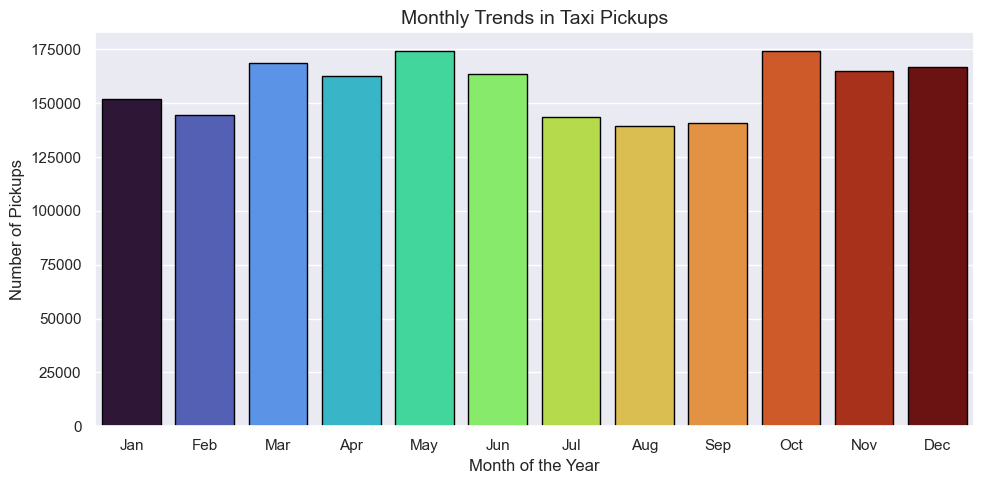

In [ ]:
# Show the monthly trends in pickups
PD['pickup_month'] = PD['tpep_pickup_datetime'].dt.month
monthly_trends = PD['pickup_month'].value_counts().sort_index().reset_index()
monthly_trends.columns = ['Month', 'Count']
plt.figure(figsize=(10, 5))
sns.barplot(data=monthly_trends, x='Month', y='Count',hue='Month', palette='turbo',  legend=False,  edgecolor='black')   
plt.title("Monthly Trends in Taxi Pickups", fontsize=14)
plt.xlabel("Month of the Year", fontsize=12)
plt.ylabel("Number of Pickups", fontsize=12)
plt.xticks(ticks=range(len(monthly_trends)), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'][:len(monthly_trends)])
plt.tight_layout()
plt.savefig("images/monthly_trends_in_pickups.png", dpi=300, bbox_inches="tight") 
plt.show()   
    

#### Financial analysis
How many trips have zero (or negative) values in the key money and distance columns?

In [ ]:
fin_cols = ["fare_amount", "tip_amount", "total_amount", "trip_distance"]
pd.DataFrame({
    "zero": (PD[fin_cols] == 0).sum(),
    "negative": (PD[fin_cols] < 0).sum(),
    "zero_%": ((PD[fin_cols] == 0).mean() * 100).round(2),
})

A zero tip is normal (cash tips are not recorded). A zero distance can happen when pickup and drop-off are in the same spot or the trip was cancelled, so those trips are kept in the main data but **left out of any per-mile or revenue analysis** using a separate copy:

In [ ]:
PD_nonzero = PD[PD["trip_distance"] > 0].copy()
PD_nonzero.shape

**Monthly revenue trend**

In [ ]:
monthly_rev = PD_nonzero.groupby(PD_nonzero["tpep_pickup_datetime"].dt.month)["total_amount"].sum()

plt.figure(figsize=(10, 5))
monthly_rev.plot(kind="line", marker="o", color="#2a9d8f")
plt.title("Monthly Revenue (5% sample)", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Total revenue ($)")
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("images/monthly_revenue.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Highest-revenue month: {monthly_rev.idxmax()}  |  Lowest: {monthly_rev.idxmin()}")

**Share of revenue by quarter**

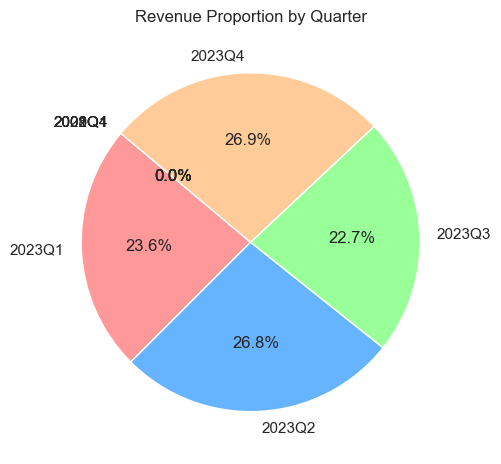

In [ ]:
Total_Rev=PD_nonzero["total_amount"].sum()
(PD_nonzero.groupby(PD_nonzero["tpep_pickup_datetime"].dt.to_period("Q"))["total_amount"]
 .sum()
 .apply(lambda x: (x / Total_Rev) * 100)
 .plot(
     kind="pie",
     autopct="%1.1f%%",
     title="Revenue Proportion by Quarter",
     ylabel="",  
     startangle=140,
     colors=['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']
 ))

plt.tight_layout()
plt.savefig("images/proportion_of_each_quarter.png", dpi=300, bbox_inches="tight")     
plt.show()

**Trip distance and fare**
Distribution of trip distance (trips under 50 miles):

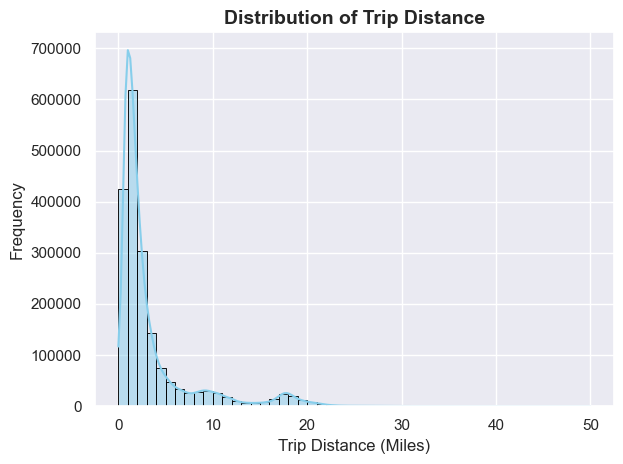

In [ ]:
sns.histplot(PD[PD['trip_distance'] < 50]['trip_distance'], bins=50, kde=True, color='skyblue', edgecolor='black')

plt.title("Distribution of Trip Distance", fontsize=14, fontweight='bold')
plt.xlabel("Trip Distance (Miles)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.savefig("images/distribution_of_trip_distance.png", dpi=300, bbox_inches="tight")     
plt.show()

In [ ]:
sample = PD_nonzero[(PD_nonzero["trip_distance"] < 50) & (PD_nonzero["fare_amount"] < 300)]
sample = sample.sample(min(50_000, len(sample)), random_state=42)   # sample so the scatter plot stays readable

plt.figure(figsize=(10, 5))
sns.scatterplot(data=sample, x="trip_distance", y="fare_amount", alpha=0.2, s=8)
plt.title("Fare Amount vs Trip Distance", fontsize=14)
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Fare Amount ($)")
plt.tight_layout()
plt.savefig("images/fare_vs_trip_distance.png", dpi=300, bbox_inches="tight")
plt.show()

corr_dist_fare = PD_nonzero["trip_distance"].corr(PD_nonzero["fare_amount"])
print(f"Correlation (trip_distance, fare_amount): {corr_dist_fare:.2f}")

**Correlations with fare and tip**
Fare vs trip duration:

In [ ]:
# Show relationship between fare and trip duration


sns.set_theme(style="darkgrid") 
plt.figure(figsize=(10, 6), dpi=100)

sns.scatterplot(
    data=PD.sample(min(50_000, len(PD)), random_state=42), 
    x='trip_duration', 
    y='fare_amount', 
    alpha=0.4,           
    color='#1f77b4',    
    edgecolor='w',       
    linewidth=0.5
)

plt.title('Fare Amount vs Trip Duration', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Trip Duration (Minutes)', fontsize=12, labelpad=10)
plt.ylabel('Fare Amount ($)', fontsize=12, labelpad=10)

plt.tight_layout()
plt.savefig("images/relationship_between_fare_and_trip_duration.png", dpi=300, bbox_inches="tight") 
plt.show()

print(f"Correlation (trip_duration, fare_amount): {PD['trip_duration'].corr(PD['fare_amount']):.2f}")

Fare vs number of passengers:

In [ ]:
pax_fare = PD[PD["passenger_count"] > 0].groupby("passenger_count")["fare_amount"].mean()

pax_fare.plot(kind="bar", color="#457b9d", figsize=(8, 4), title="Average Fare by Passenger Count")
plt.xlabel("Passenger Count")
plt.ylabel("Average Fare ($)")
plt.xticks(rotation=0)
plt.savefig("images/fare_by_passenger_count.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Correlation (passenger_count, fare_amount): {PD['passenger_count'].corr(PD['fare_amount']):.2f}")

Tip vs trip distance:

In [ ]:
# Show relationship between tip and trip distance
PD.sample(min(50_000, len(PD)), random_state=42).plot(
    kind="scatter",
    x="trip_distance",
    y="tip_amount",
    color="red",
    figsize=(10, 5),
    title="Relationship between tip and trip distance",
)
plt.xlabel("Trip Distance")
plt.ylabel("Tip Amount")
plt.savefig("images/tip_and_trip_distance.png", dpi=300, bbox_inches="tight") 
plt.show()

print(f"Correlation (trip_distance, tip_amount): {PD['trip_distance'].corr(PD['tip_amount']):.2f}")

In [ ]:
# All four correlations in one table
corr_cols = ["fare_amount", "tip_amount", "trip_distance", "trip_duration", "passenger_count"]
plt.figure(figsize=(7, 5))
sns.heatmap(PD_nonzero[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("images/correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

**Payment types**

`payment_type` codes: 1 = Credit card, 2 = Cash, 3 = No charge, 4 = Dispute, 5 = Unknown, 6 = Voided, 0 = Flex fare.

In [ ]:
payment_labels = {0: "Flex fare", 1: "Credit card", 2: "Cash", 3: "No charge", 4: "Dispute", 5: "Unknown", 6: "Voided"}
payment_share = PD["payment_type"].map(payment_labels).value_counts(normalize=True) * 100
print(payment_share.round(2))

payment_share.plot(kind="bar", color="#e76f51", figsize=(8, 4), title="Share of Trips by Payment Type")
plt.ylabel("% of trips")
plt.xticks(rotation=0)
plt.savefig("images/payment_type_share.png", dpi=300, bbox_inches="tight")
plt.show()

### 3.2 Detailed EDA: insights and strategies
#### Operational efficiency

**Slowest routes by hour.** For each route (pickup zone → drop-off zone) and hour, average speed = average distance / average duration. Only routes with at least 30 trips in that hour are kept so a few odd trips do not dominate.

In [ ]:
route_trips = PD_nonzero[(PD_nonzero["trip_duration"] > 1)].copy()
route_trips["pickup_hour"] = route_trips["tpep_pickup_datetime"].dt.hour

route_speed = (route_trips
               .groupby(["PULocationID", "DOLocationID", "pickup_hour"])
               .agg(trips=("trip_distance", "size"),
                    avg_distance=("trip_distance", "mean"),
                    avg_duration_min=("trip_duration", "mean"))
               .reset_index())
route_speed = route_speed[route_speed["trips"] >= 30]
route_speed["speed_mph"] = route_speed["avg_distance"] / (route_speed["avg_duration_min"] / 60)

slowest = route_speed.nsmallest(10, "speed_mph").copy()
slowest["route"] = [f"{zone_label(a)} → {zone_label(b)}" for a, b in zip(slowest["PULocationID"], slowest["DOLocationID"])]
slowest[["route", "pickup_hour", "trips", "avg_distance", "avg_duration_min", "speed_mph"]].round(2)

In [ ]:
# Average speed across all trips by hour – shows when the city is most congested
hourly_speed = route_trips.groupby("pickup_hour").apply(
    lambda d: d["trip_distance"].sum() / (d["trip_duration"].sum() / 60))

hourly_speed.plot(kind="line", marker="o", color="#264653", figsize=(10, 5),
                  title="Average Taxi Speed by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Speed (mph)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("images/avg_speed_by_hour.png", dpi=300, bbox_inches="tight")
plt.show()

Knowing slow routes and slow hours helps dispatch: a cab stuck on a slow route earns less per hour, so drivers can be steered to faster, high-demand routes at those times.

**Busiest hour**

In [ ]:
hourly_counts = PD["tpep_pickup_datetime"].dt.hour.value_counts().sort_index()

hourly_counts.plot(kind="bar", color="red", figsize=(10, 5), title="Trips per Hour (5% sample)")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.savefig("images/trips_per_hour.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Busiest hour: {hourly_counts.idxmax()}:00 with {hourly_counts.max():,} trips in the sample")

The sample holds 5% of trips, so the real numbers are found by dividing by the sampling fraction.

**Estimated actual trips in the five busiest hours (full year 2023):**

In [ ]:
top5 = hourly_counts.nlargest(5)
pd.DataFrame({
    "trips_in_sample": top5,
    "estimated_actual_trips": (top5 / SAMPLE_FRACTION).round().astype(int),
})

**Weekdays vs weekends**

<Figure size 1200x600 with 0 Axes>

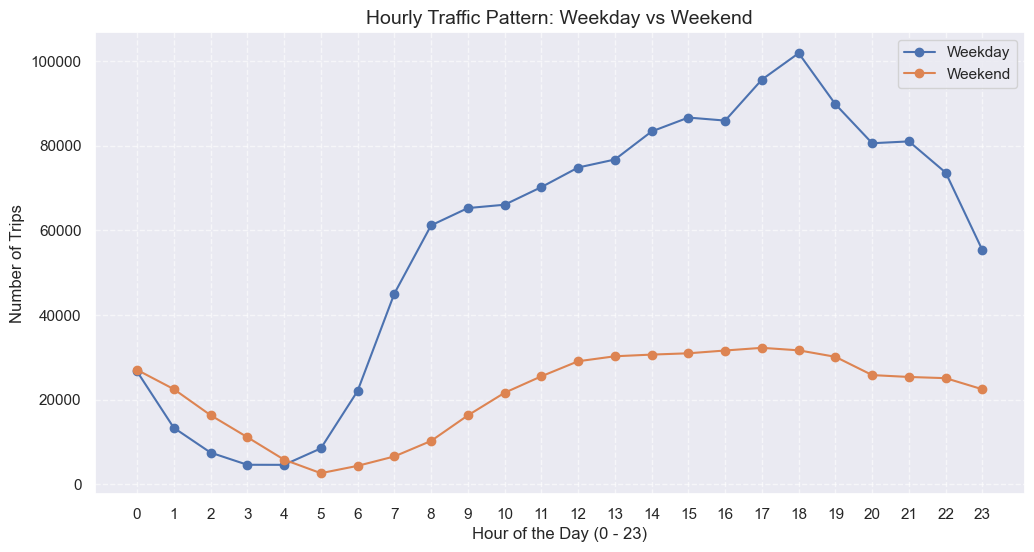

In [ ]:
# Compare traffic trends for the week days and weekends

PD["pickup_hour"] = PD["tpep_pickup_datetime"].dt.hour
PD["day_of_week"] = PD["tpep_pickup_datetime"].dt.dayofweek 

PD["is_weekend"] = PD["day_of_week"].isin([5, 6])

traffic_pattern = ( PD.groupby(["pickup_hour", "is_weekend"]).size().unstack(level=1)
)
   
traffic_pattern.columns = ["Weekday", "Weekend"]

plt.figure(figsize=(12, 6))
traffic_pattern.plot(kind="line", marker="o", figsize=(12, 6))
plt.title("Hourly Traffic Pattern: Weekday vs Weekend", fontsize=14)
plt.xlabel("Hour of the Day (0 - 23)")
plt.ylabel("Number of Trips")
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(["Weekday", "Weekend"])
plt.savefig("images/week_days_and_weekends.png", dpi=300, bbox_inches="tight")     
plt.show()

- **Weekdays** have a clear commute shape: a sharp rise from 6 AM to 8 AM and the main peak at **6 PM**.
- **Weekends** are flatter, with a broad plateau from about noon to 7 PM.
- Between **midnight and 3 AM, weekends are busier than weekdays** – late-night leisure trips.

So weekday supply should follow commute hours, while weekend supply should shift later into the night.

**Top 10 pickup and drop-off zones – hourly trends**

<Figure size 1000x400 with 0 Axes>

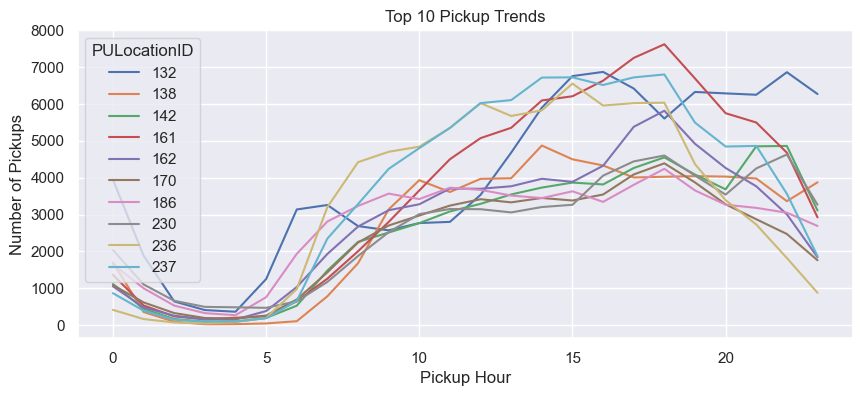

In [ ]:
# Find top 10 pickup and dropoff zones

PD["pickup_hour"] = PD["tpep_pickup_datetime"].dt.hour
top_p = PD["PULocationID"].value_counts().head(10).index
top_d = PD["DOLocationID"].value_counts().head(10).index

plt.figure(figsize=(10, 4))
PD[PD["PULocationID"].isin(top_p)].groupby(
    ["pickup_hour", "PULocationID"]
).size().unstack().plot(figsize=(10, 4), title="Top 10 Pickup Trends")
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Pickups")
plt.savefig("images/pickup_and_dropoff_zones.png", dpi=300, bbox_inches="tight") 
    
plt.show()

<Figure size 1000x400 with 0 Axes>

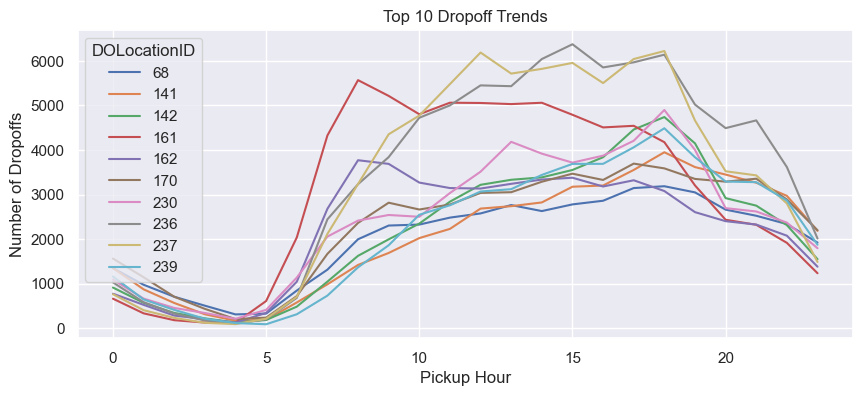

In [ ]:
plt.figure(figsize=(10, 4))
PD[PD["DOLocationID"].isin(top_d)].groupby(
    ["pickup_hour", "DOLocationID"]
).size().unstack().plot(figsize=(10, 4), title="Top 10 Dropoff Trends")
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Dropoffs")
plt.savefig("images/top_10_dropoff_trends.png", dpi=300, bbox_inches="tight") 
plt.show()

In [ ]:
top_pickup_zones = PD["PULocationID"].value_counts().head(10)
top_dropoff_zones = PD["DOLocationID"].value_counts().head(10)
pd.DataFrame({
    "top_pickup_zone": [zone_label(z) for z in top_pickup_zones.index],
    "pickups": top_pickup_zones.values,
    "top_dropoff_zone": [zone_label(z) for z in top_dropoff_zones.index],
    "dropoffs": top_dropoff_zones.values,
})

**Pickup / drop-off ratio by zone.** A ratio above 1 means more people leave the zone than arrive (cabs get used up there); below 1 means cabs pile up.

In [ ]:
pickups = PD["PULocationID"].value_counts()
dropoffs = PD["DOLocationID"].value_counts()
ratios = pd.DataFrame({"pickups": pickups, "dropoffs": dropoffs}).fillna(0)

# Ignore very small zones so a zone with 3 pickups / 1 drop-off does not top the list
valid_ratios = ratios[(ratios["pickups"] >= 100) & (ratios["dropoffs"] >= 100)].copy()
valid_ratios["ratio"] = valid_ratios["pickups"] / valid_ratios["dropoffs"]
valid_ratios["zone"] = [zone_label(z) for z in valid_ratios.index]

print("Highest pickup/drop-off ratios:")
print(valid_ratios.nlargest(10, "ratio")[["zone", "pickups", "dropoffs", "ratio"]].round(2).to_string())
print("\nLowest pickup/drop-off ratios:")
print(valid_ratios.nsmallest(10, "ratio")[["zone", "pickups", "dropoffs", "ratio"]].round(2).to_string())

In [ ]:
top_10 = valid_ratios["ratio"].nlargest(10)
bottom_10 = valid_ratios["ratio"].nsmallest(10)

top_10.plot(
    kind="bar",
    color="skyblue",
    figsize=(8, 4),
    title="Top 10 Highest Pickup/Dropoff Ratios",
)
plt.xlabel("Zone ID")
plt.ylabel("Ratio")
plt.savefig("images/top_10_bottom_pickup.png", dpi=300, bbox_inches="tight") 
plt.show()

In [ ]:
bottom_10.plot(
    kind="bar",
    color="salmon",
    figsize=(8, 4),
    title="Top 10 Lowest Pickup/Dropoff Ratios",
)
plt.xlabel("Zone ID")
plt.ylabel("Ratio")
plt.savefig("images/10_and_bottom_10_pickup.png", dpi=300, bbox_inches="tight") 
plt.show()

**Night hours (11 PM – 5 AM): busiest zones**

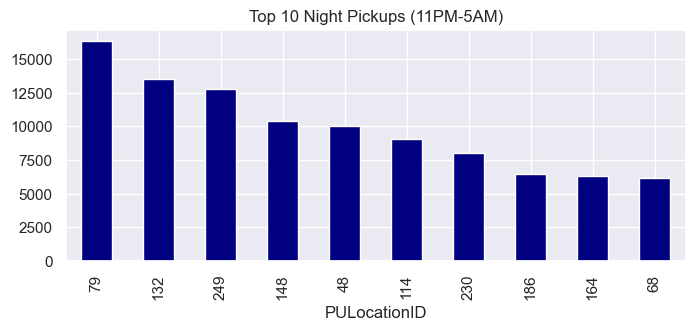

In [ ]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
night_df = PD[PD["tpep_pickup_datetime"].dt.hour.isin([23, 0, 1, 2, 3, 4])]


night_df["PULocationID"].value_counts().head(10).plot(
    kind="bar",
    color="navy",
    figsize=(8, 3),
    title="Top 10 Night Pickups (11PM-5AM)")
    
plt.savefig("images/night_hours_11pm_to_5am.png", dpi=300, bbox_inches="tight") 
plt.show()

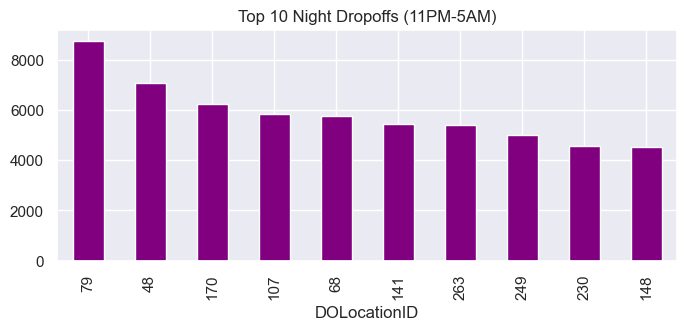

In [ ]:
night_df["DOLocationID"].value_counts().head(10).plot(
    kind="bar",
    color="purple",
    figsize=(8, 3),
    title="Top 10 Night Dropoffs (11PM-5AM)")
plt.savefig("images/dropoff_top_10_zones.png", dpi=300, bbox_inches="tight") 
plt.show()

**Revenue share: night vs day**

In [ ]:
night_hours = [23, 0, 1, 2, 3, 4]
is_night = PD_nonzero["tpep_pickup_datetime"].dt.hour.isin(night_hours)

night_revenue = PD_nonzero.loc[is_night, "total_amount"].sum()
total_revenue = PD_nonzero["total_amount"].sum()
night_share = night_revenue / total_revenue * 100
day_share = 100 - night_share
print(f"Night share: {night_share:.1f}%  |  Day share: {day_share:.1f}%")

In [ ]:
plt.figure(figsize=(6, 6))
plt.pie(
    [day_share, night_share],
    labels=["Daytime", "Nighttime"],
    autopct="%1.1f%%",
    colors=["#4CAF50", "#2196F3"],
    explode=(0, 0.1),
    startangle=140,
)
plt.title("Revenue Share: Daytime vs Nighttime Hours", fontsize=12)
plt.savefig("images/filter_for_night_hours_11_pm_to_5_am.png", dpi=300, bbox_inches="tight") 
plt.show()

#### Pricing strategy
**Average fare per mile per passenger** (e.g. if 3 passengers pay $3/mile, it is $1/mile per passenger):

passenger_count
1.0    10.703638
2.0     6.636947
3.0     3.657477
4.0     4.235989
5.0     1.733319
6.0     1.568232
Name: fare_per_mile_per_passenger, dtype: float64


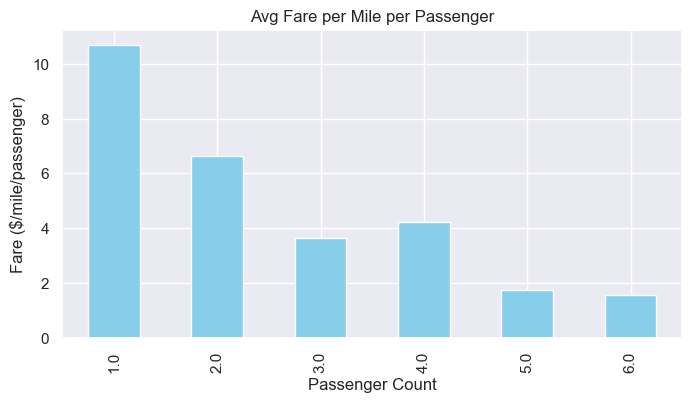

In [ ]:
# Analyse the fare per mile per passenger for different passenger counts

valid_trips = PD[(PD["trip_distance"] > 0) & (PD["passenger_count"] > 0)].copy()
valid_trips["fare_per_mile"] = (
    valid_trips["fare_amount"] / valid_trips["trip_distance"]
)
valid_trips["fare_per_mile_per_passenger"] = (
    valid_trips["fare_per_mile"] / valid_trips["passenger_count"]
)

avg_fare = valid_trips.groupby("passenger_count")[
    "fare_per_mile_per_passenger"
].mean()
print(avg_fare)


avg_fare.plot(
    kind="bar",
    color="skyblue",
    figsize=(8, 4),
    title="Avg Fare per Mile per Passenger",
)
plt.xlabel("Passenger Count")
plt.ylabel("Fare ($/mile/passenger)")
plt.savefig("images/passenger.png", dpi=300, bbox_inches="tight") 
plt.show()

**Average fare per mile by hour and by day**

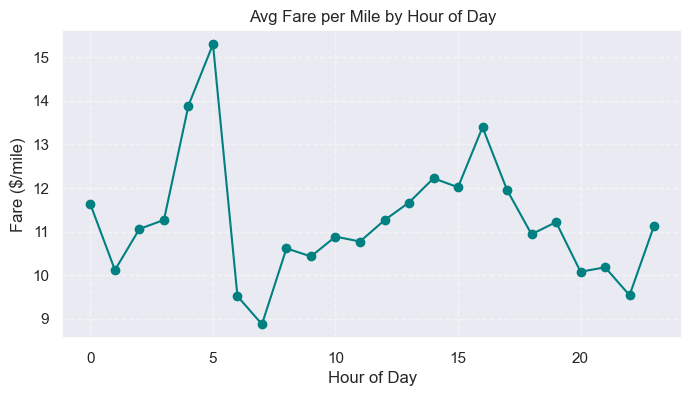

In [ ]:
# Compare the average fare per mile for different days and for different times of the day

valid_trips = PD[PD["trip_distance"] > 0].copy()
valid_trips["fare_per_mile"] = (
    valid_trips["fare_amount"] / valid_trips["trip_distance"]
)

valid_trips["hour"] = valid_trips["tpep_pickup_datetime"].dt.hour
valid_trips["day_name"] = valid_trips["tpep_pickup_datetime"].dt.day_name()

valid_trips.groupby("hour")["fare_per_mile"].mean().plot(
    kind="line",
    marker="o",
    figsize=(8, 4),
    color="teal",
    title="Avg Fare per Mile by Hour of Day",
)
plt.xlabel("Hour of Day")
plt.ylabel("Fare ($/mile)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("images/avg_fare_per_mile_hour.png", dpi=300, bbox_inches="tight")
plt.show()

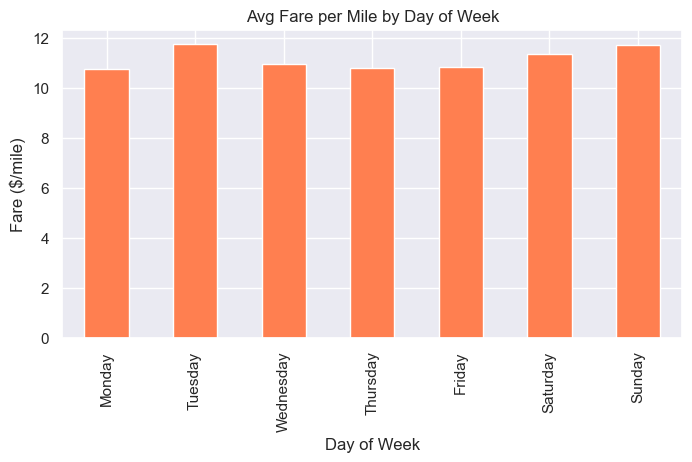

In [ ]:
days_order = ["Monday",  "Tuesday","Wednesday", "Thursday","Friday","Saturday","Sunday"]
   
valid_trips.groupby("day_name")["fare_per_mile"].mean().reindex(days_order).plot(kind="bar",color="coral",figsize=(8, 4), title="Avg Fare per Mile by Day of Week")
   
plt.xlabel("Day of Week")
plt.ylabel("Fare ($/mile)")
plt.savefig("images/avg_fare_per_mile_day.png", dpi=300, bbox_inches="tight")
plt.show()

Fare per mile is highest around **4–5 AM** (short airport/night trips with fixed charges) and around **4 PM** (slow traffic, so the time-based part of the meter adds up). It is lowest at **6–7 AM**, when roads are clear and trips are longer.

**Fare per mile by vendor across hours**

VendorID: 1 = Creative Mobile Technologies, 2 = VeriFone (Curb).

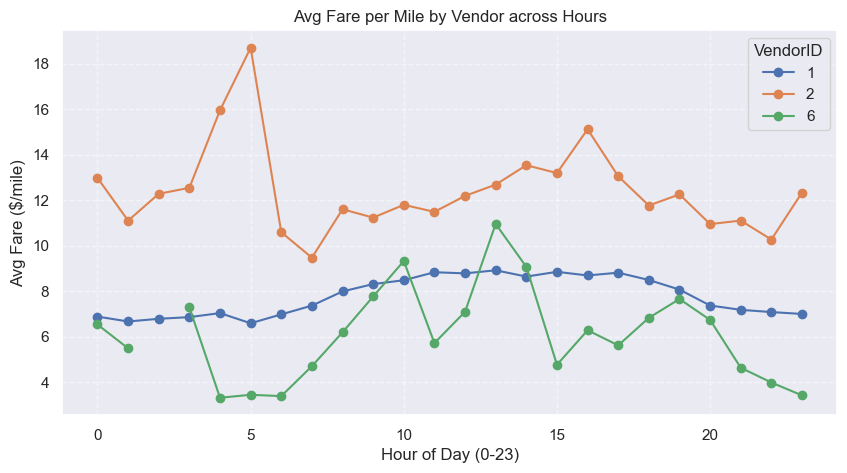

In [ ]:
# Compare fare per mile for different vendors


valid_trips = PD[PD["trip_distance"] > 0].copy()
valid_trips["fare_per_mile"] = (
    valid_trips["fare_amount"] / valid_trips["trip_distance"]
)
valid_trips["hour"] = valid_trips["tpep_pickup_datetime"].dt.hour

vendor_hourly = (
    valid_trips.groupby(["hour", "VendorID"])["fare_per_mile"]
    .mean()
    .unstack()
)

vendor_hourly.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Avg Fare per Mile by Vendor across Hours",
)
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Avg Fare ($/mile)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("images/vendor_hourly_fare.png", dpi=300, bbox_inches="tight")
plt.show()

**Fare per mile by distance tier and vendor** (≤2 miles, 2–5 miles, >5 miles)

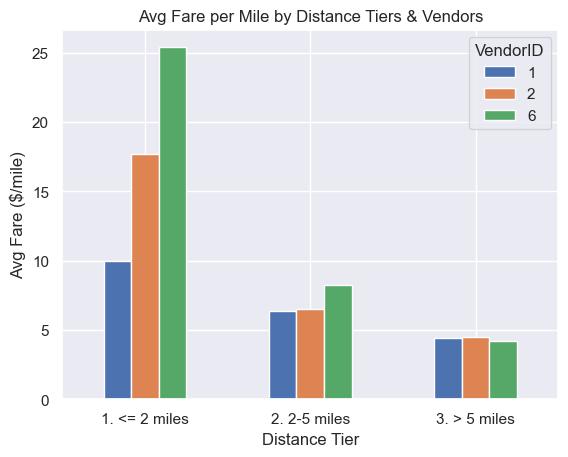

In [ ]:
# Defining distance tiers

v_trips = PD[PD["trip_distance"] > 0].copy()
v_trips["fare_per_mile"] = v_trips["fare_amount"] / v_trips["trip_distance"]

conditions = [v_trips["trip_distance"] <= 2, v_trips["trip_distance"] <= 5]
choices = ["1. <= 2 miles", "2. 2-5 miles"]
v_trips["tier"] = np.select(conditions, choices, default="3. > 5 miles")

v_trips.groupby(["tier", "VendorID"])["fare_per_mile"].mean().unstack().plot(
    kind="bar", title="Avg Fare per Mile by Distance Tiers & Vendors"
)
plt.xlabel("Distance Tier")
plt.ylabel("Avg Fare ($/mile)")
plt.xticks(rotation=0)
plt.savefig("images/tiered_fare_per_mile.png", dpi=300, bbox_inches="tight")
plt.show()

#### Customer experience
**Average tip % by distance, passenger count and hour**

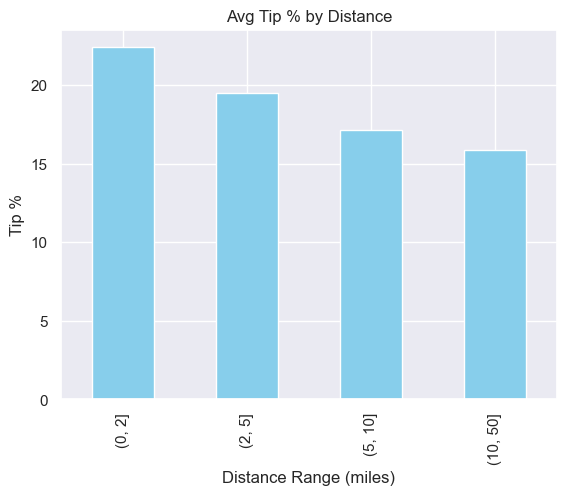

In [ ]:
#  Analyze tip percentages based on distances, passenger counts and pickup times


valid_trips = PD[PD["fare_amount"] > 0].copy()
valid_trips["tip_pct"] = (
    valid_trips["tip_amount"] / valid_trips["fare_amount"]
) * 100
valid_trips["hour"] = valid_trips["tpep_pickup_datetime"].dt.hour


valid_trips.groupby(pd.cut(valid_trips["trip_distance"], bins=[0, 2, 5, 10, 50]))[
    "tip_pct"
].mean().plot(kind="bar", color="skyblue", title="Avg Tip % by Distance")
plt.xlabel("Distance Range (miles)")
plt.ylabel("Tip %")
plt.savefig("images/tip_pct_by_distance.png", dpi=300, bbox_inches="tight")
plt.show()

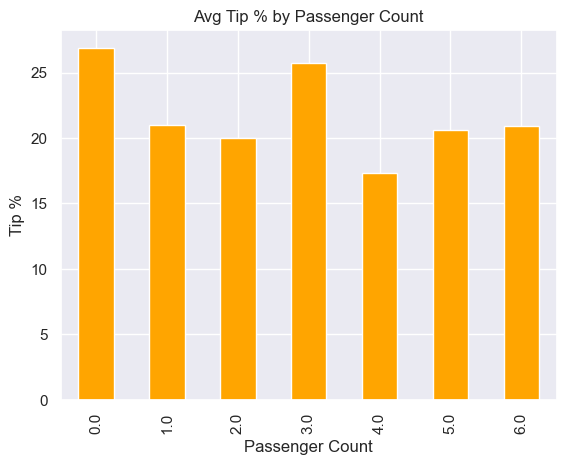

In [ ]:
valid_trips.groupby("passenger_count")["tip_pct"].mean().plot(
    kind="bar", color="orange", title="Avg Tip % by Passenger Count"
)
plt.xlabel("Passenger Count")
plt.ylabel("Tip %")
plt.savefig("images/tip_pct_by_passenger_count.png", dpi=300, bbox_inches="tight")
plt.show()

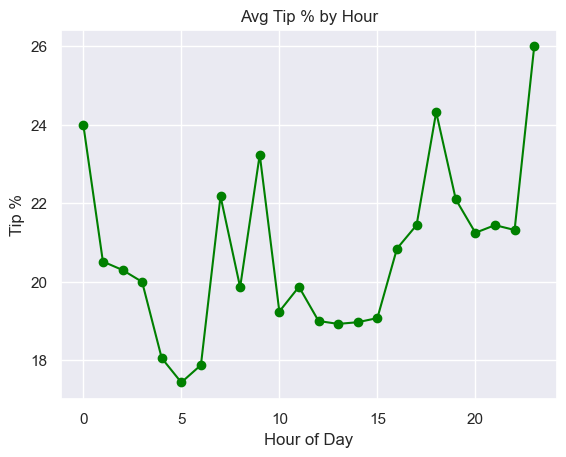

In [ ]:
valid_trips.groupby("hour")["tip_pct"].mean().plot(
    kind="line", marker="o", color="green", title="Avg Tip % by Hour"
)
plt.xlabel("Hour of Day")
plt.ylabel("Tip %")
plt.savefig("images/tip_pct_by_hour.png", dpi=300, bbox_inches="tight")
plt.show()

**Low tips (<10%) vs high tips (>25%)**

                Low Tips (<10%)  High Tips (>25%)
Avg Distance           4.342695          2.975476
Avg Fare              21.836820         14.459560
Avg Passengers         1.383411          1.344266


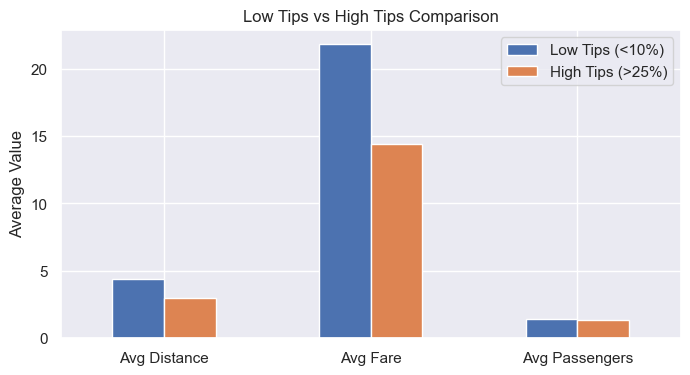

In [ ]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%

low_tips = valid_trips[valid_trips["tip_pct"] < 10]
high_tips = valid_trips[valid_trips["tip_pct"] > 25]

comp = pd.DataFrame(
    {
        "Low Tips (<10%)": [
            low_tips["trip_distance"].mean(),
            low_tips["fare_amount"].mean(),
            low_tips["passenger_count"].mean(),
        ],
        "High Tips (>25%)": [
            high_tips["trip_distance"].mean(),
            high_tips["fare_amount"].mean(),
            high_tips["passenger_count"].mean(),
        ],
    },
    index=["Avg Distance", "Avg Fare", "Avg Passengers"],
)

print(comp)
comp.plot(kind="bar", figsize=(8, 4), title="Low Tips vs High Tips Comparison")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.savefig("images/low_vs_high_tips.png", dpi=300, bbox_inches="tight")
plt.show()

Tip % falls steadily as distance grows (about 22% for trips under 2 miles vs about 16% for trips over 10 miles). High-tip trips are shorter and cheaper on average (≈3.0 miles / $14.5) than low-tip trips (≈4.3 miles / $21.8). Passenger count barely differs between the two groups, so **trip length and fare size are the main drivers of a low tip %** – riders tend to tip a round amount rather than a fixed percentage.

**Passenger count across hours and days**

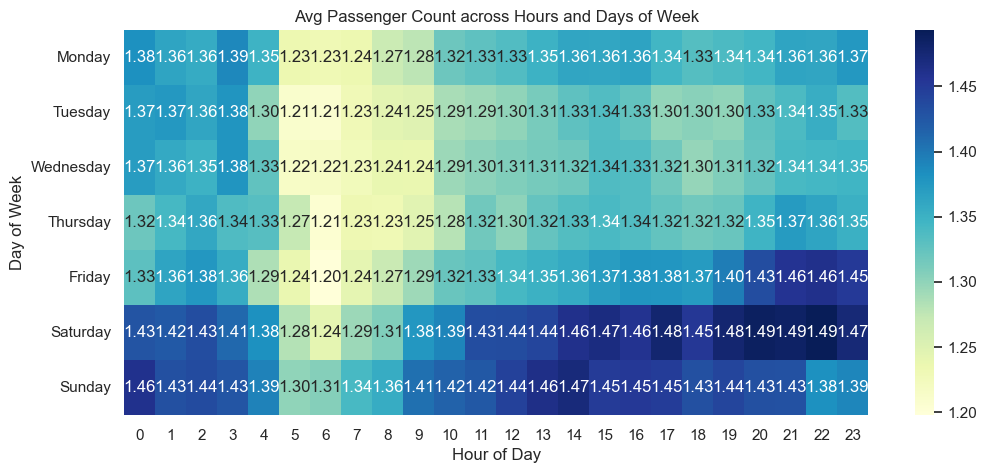

In [ ]:
# See how passenger count varies across hours and days
PD["hour"] = PD["tpep_pickup_datetime"].dt.hour
PD["day_name"] = PD["tpep_pickup_datetime"].dt.day_name()

days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]


piv = (
    PD.pivot_table(
        index="day_name", columns="hour", values="passenger_count", aggfunc="mean"
    )
    .reindex(days_order)
)
plt.figure(figsize=(12, 5))
sns.heatmap(piv, cmap="YlGnBu", annot=True, fmt=".2f")
plt.title("Avg Passenger Count across Hours and Days of Week")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.savefig("images/passenger_count_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 4. Conclusion
### Key numbers
All headline numbers used in the conclusion and in the README, recomputed from the cleaned data:

In [ ]:
key_numbers = {
    "Rows after cleaning": f"{len(PD):,}",
    "Busiest hour": f"{hourly_counts.idxmax()}:00 ({hourly_counts.max():,} trips in sample)",
    "Quietest hour": f"{hourly_counts.idxmin()}:00 ({hourly_counts.min():,} trips in sample)",
    "Night revenue share (11PM-5AM)": f"{night_share:.1f}%",
    "Corr distance vs fare": f"{corr_dist_fare:.2f}",
    "Credit card share of trips": f"{payment_share.get('Credit card', 0):.1f}%",
}
q_share = (PD_nonzero.groupby(PD_nonzero["tpep_pickup_datetime"].dt.quarter)["total_amount"].sum()
           / PD_nonzero["total_amount"].sum() * 100)
for q, v in q_share.items():
    key_numbers[f"Q{q} revenue share"] = f"{v:.1f}%"
pd.Series(key_numbers, name="value").to_frame()

### Final insights
1. **Demand peaks in the evening commute.** Weekday trips climb from 6 AM and peak at **6 PM**; the quietest hours are **4–5 AM**.
2. **Night is a small slice of revenue.** Trips between 11 PM and 5 AM bring only about **11.5%** of revenue – but on weekends, midnight to 3 AM is busier than on weekdays.
3. **Revenue is spread evenly across the year.** Each quarter brings roughly 23–27% of revenue, so there is no strong seasonal low season.
4. **Distance drives fare; tips shrink as a share of longer trips.** Tip % falls from about 22% on short trips to about 16% on trips over 10 miles.
5. **Shared rides are far cheaper per person.** Fare per mile per passenger drops from about **$10.70** for solo riders to about **$1.57** with 6 passengers.

### Recommendations
**Routing and dispatching**
- On weekdays, put more cabs near business districts and airports for the **7–10 AM** ramp-up and the **5–8 PM** peak.
- Use the slow-route table above to steer drivers away from congested routes at peak hours.

**Positioning cabs across zones**
- Move cabs from zones with a low pickup/drop-off ratio (cabs pile up) to zones with a high ratio (cabs get used up).
- On Friday and Saturday nights, keep more cabs active after midnight near the top night-time pickup zones.

**Pricing**
- A mild rush-hour surcharge (+10–15%) on the busiest routes during 5–8 PM can raise revenue where demand is strongest.
- Small off-peak offers (late night on weekdays, mid-morning) can keep drivers busy in slow hours.
- Promote shared rides for groups – the per-person price advantage is large.